In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
df = pd.read_csv("online_retail_clean.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.isnull().sum())

   InvoiceNo StockCode                          Description  Quantity  \
0     536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER       6.0   
1     536365     71053                  WHITE METAL LANTERN       6.0   
2     536365    84406B       CREAM CUPID HEARTS COAT HANGER       8.0   
3     536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE       6.0   
4     536365    84029E       RED WOOLLY HOTTIE WHITE HEART.       6.0   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
Dataset shape: (273147, 9)
InvoiceNo      0
StockCode      0
Description    0
Quantity       1
InvoiceDate    1
UnitPrice  

In [ ]:
df = df.drop_duplicates()
df = df.dropna(subset=["CustomerID", "InvoiceDate"])

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.dropna(subset=["Quantity", "UnitPrice"])

df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned data:", df.shape)

Cleaned data: (273146, 9)


In [ ]:
today = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (today - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346           263          1  77183.60
12347            67          5   2790.86
12348            12          4   1437.24
12350           247          1    294.40
12352             9          6   1154.01


In [ ]:
X = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("RFM scaling completed!")

RFM scaling completed!


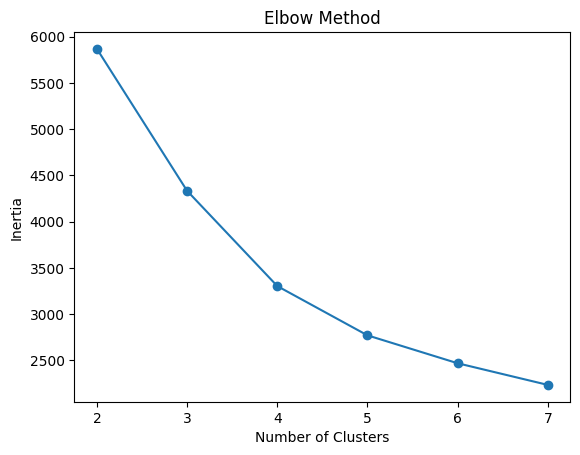

In [ ]:
inertia = []

for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(2, 8), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(rfm["KMeans_Cluster"].value_counts())

KMeans_Cluster
1    1407
0    1014
3     702
2     571
Name: count, dtype: int64


In [ ]:
profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print(profile)

                Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
KMeans_Cluster                                                     
0                    1014        82.74           3.45       1502.49
1                    1407       170.92           1.23        288.87
2                     571        17.26          12.12       6944.57
3                     702        12.61           1.93        634.56


In [ ]:
dbscan = DBSCAN(eps=0.7, min_samples=10)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(rfm["DBSCAN_Cluster"].value_counts())

DBSCAN_Cluster
 0    3648
-1      46
Name: count, dtype: int64


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Variance explained:", pca.explained_variance_ratio_.sum())

Variance explained: 0.9291816163613958


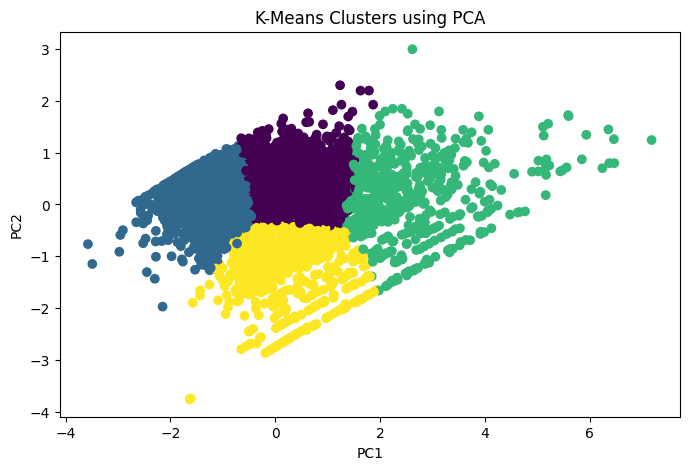

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters using PCA")
plt.show()

In [ ]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

print("t-SNE completed!")

t-SNE completed!


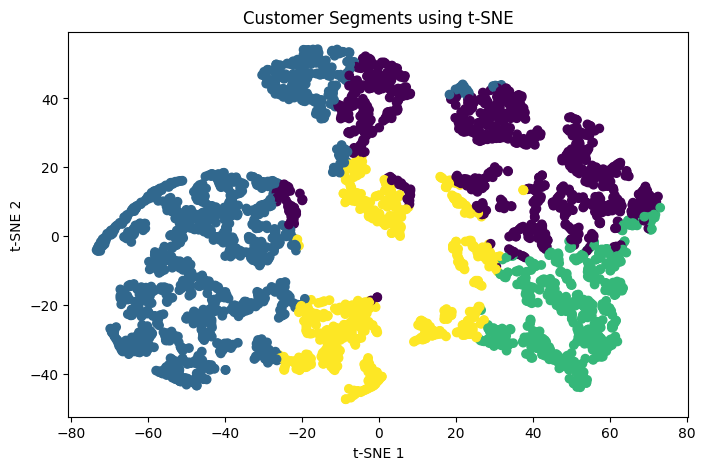

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segments using t-SNE")
plt.show()

In [ ]:
r_median = rfm["Recency"].median()
f_median = rfm["Frequency"].median()
m_median = rfm["Monetary"].median()

def persona(row):
    if (
        row["Recency"] <= r_median
        and row["Frequency"] >= f_median
        and row["Monetary"] >= m_median
    ):
        return "Champions"
    elif row["Recency"] > r_median:
        return "At-Risk Customers"
    elif row["Frequency"] <= f_median:
        return "New or Occasional Customers"
    else:
        return "Loyal Customers"

rfm["Persona"] = rfm.apply(persona, axis=1)

print(rfm["Persona"].value_counts())

Persona
At-Risk Customers              1847
Champions                      1172
New or Occasional Customers     583
Loyal Customers                  92
Name: count, dtype: int64


In [ ]:
rfm.to_csv("customer_segmentation_results.csv")

profile.to_csv("customer_personas.csv")

print("Results saved successfully!")

Results saved successfully!


In [ ]:
# K-Means evaluation
kmeans_score = silhouette_score(X_scaled, rfm["KMeans_Cluster"])

# DBSCAN evaluation (exclude noise)
mask = rfm["DBSCAN_Cluster"] != -1
labels = rfm.loc[mask, "DBSCAN_Cluster"]

if labels.nunique() >= 2:
    dbscan_score = silhouette_score(X_scaled[mask], labels)
else:
    dbscan_score = None

print("K-Means Silhouette Score:", round(kmeans_score, 3))
print("DBSCAN Silhouette Score:", dbscan_score)

K-Means Silhouette Score: 0.369
DBSCAN Silhouette Score: None


In [ ]:
marketing_actions = {
    "Champions": "VIP rewards, early access, referral offers",
    "Loyal Customers": "Loyalty points, product bundles",
    "New or Occasional Customers": "Welcome offers, second-purchase discounts",
    "At-Risk Customers": "Win-back emails, personalized offers"
}

rfm["Marketing_Action"] = rfm["Persona"].map(marketing_actions)

print(
    rfm[[
        "Recency", "Frequency", "Monetary",
        "KMeans_Cluster", "DBSCAN_Cluster",
        "Persona", "Marketing_Action"
    ]].head(10)
)

            Recency  Frequency  Monetary  KMeans_Cluster  DBSCAN_Cluster  \
CustomerID                                                                 
12346           263          1  77183.60               0              -1   
12347            67          5   2790.86               0               0   
12348            12          4   1437.24               0               0   
12350           247          1    294.40               1               0   
12352             9          6   1154.01               2               0   
12353           141          1     89.00               1               0   
12354           169          1   1079.40               1               0   
12355           151          1    459.40               1               0   
12356           182          2   2429.08               0               0   
12358            88          1    404.86               1               0   

                      Persona                            Marketing_Action  
CustomerID 